# Example of the aitlas toolbox in the context of object detection in remote sensing images

This subset of COWC contains single pixel labels used originally for a counting task. We here showcase an example where the pixels are translated into a bounding box for object detection.

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import COWCMObjectDetectionDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Total number of patches: 29549


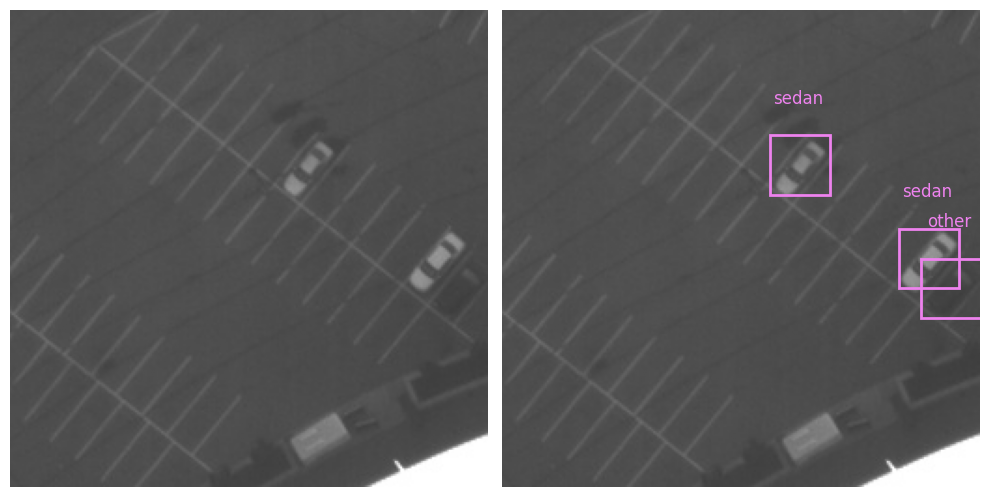

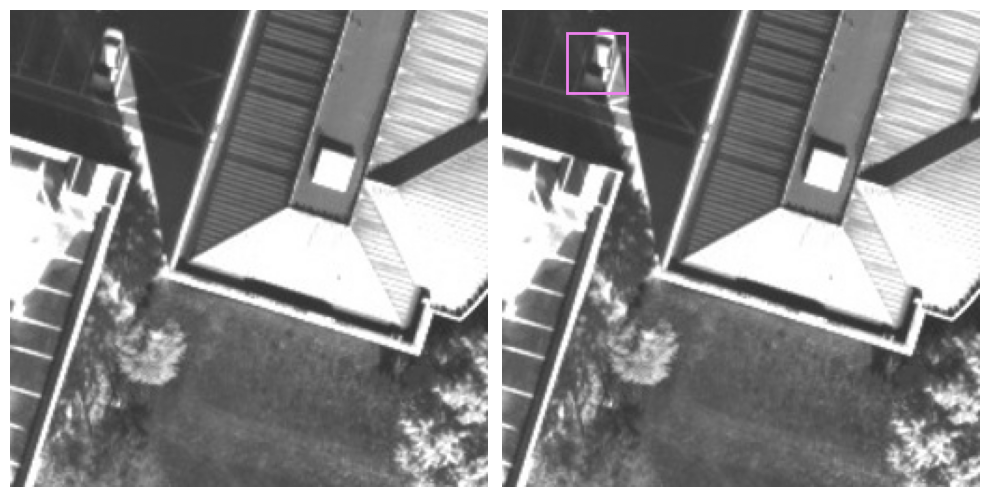

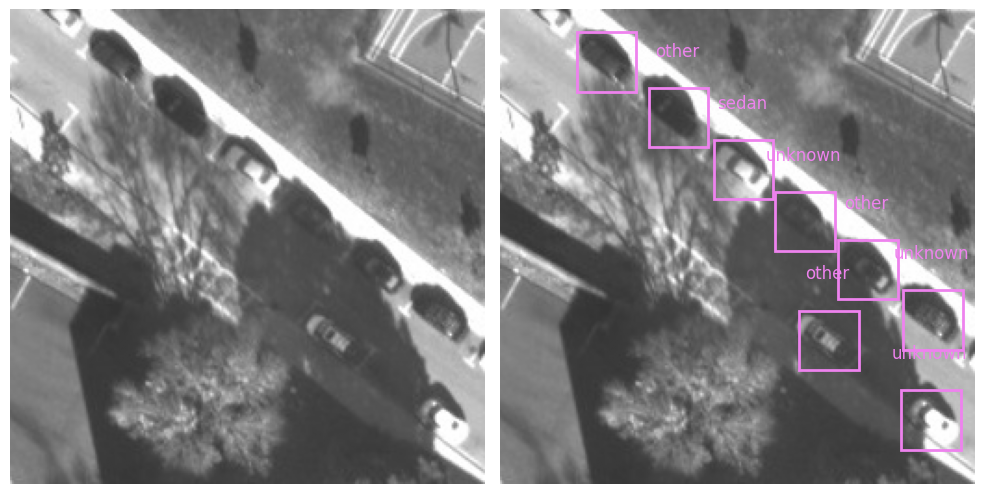

In [ ]:
dataset_config = {
    "data_dir": "./data/cowc_m_object_detection/datasets/DetectionPatches_256x256/",

}
dataset = COWCMObjectDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}") 
dataset.show_image(10);
dataset.show_image(50);
dataset.show_image(700);

In [10]:
dataset.data_distribution_table()

,Label,Count
0,other,61055
1,pickup,10987
2,sedan,59714
3,unknown,11824


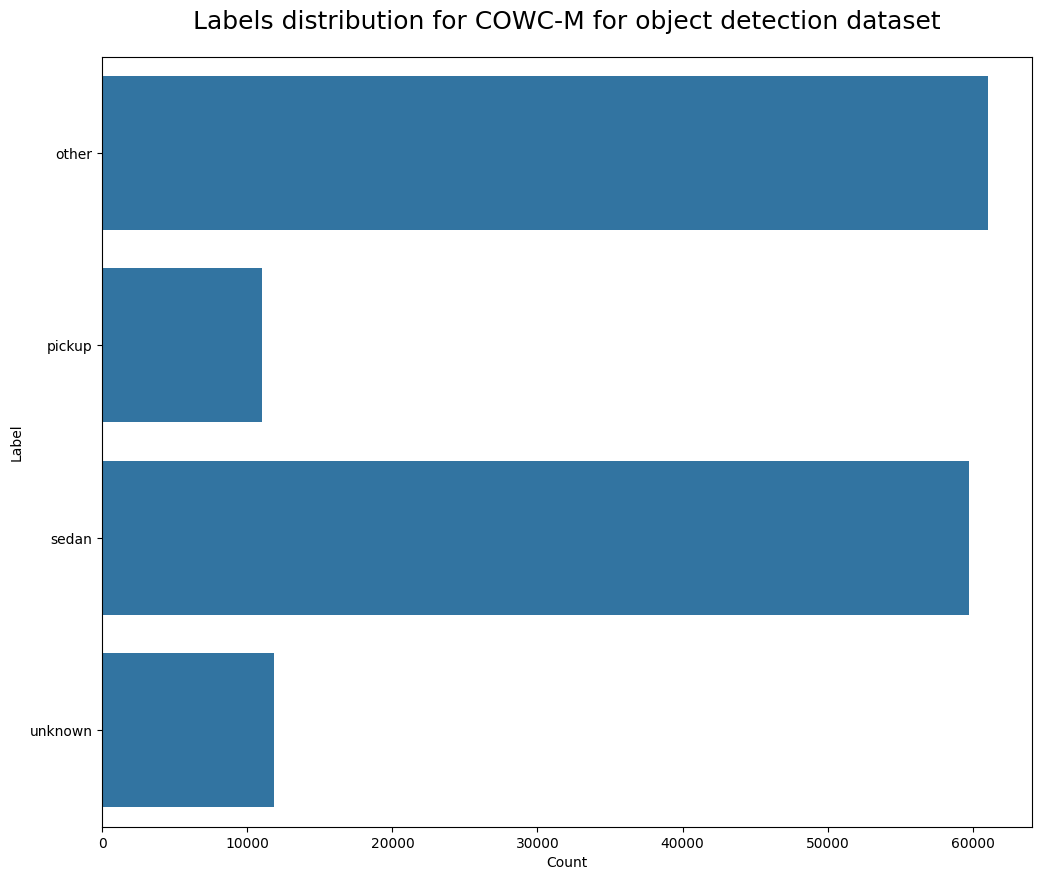

In [49]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/cowc_m_object_detection/datasets/DetectionPatches_256x256/",
    "csv_file": "./data/cowc_m_object_detection/datasets/DetectionPatches_256x256/cowc_m_object_detection_train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = COWCMObjectDetectionDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 23673


## Create the model

In [ ]:
epochs = 5
model_directory = "./data/experiments/cowc_m_object_detection"
model_config = {
    "num_classes": 5,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [13]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-03 14:27:57,142 INFO Starting training.
training: 100%|██████████| 2960/2960 [16:36<00:00,  2.97it/s]
2025-11-03 14:44:33,571 INFO epoch: 1, time: 996, loss:  0.25826
testing on train set: 100%|██████████| 2960/2960 [08:52<00:00,  5.56it/s]
2025-11-03 14:54:29,330 INFO map:0.5608089566230774, map_50:0.756244957447052, map_75:0.6910140514373779, map_small:0.12417766451835632, map_medium:0.5608528256416321, map_large:-1.0, mar_1:0.31586650013923645, mar_10:0.615394651889801, mar_100:0.6435951590538025, mar_small:0.15000000596046448, mar_medium:0.6436936855316162, mar_large:-1.0, map_per_class:tensor(0.6276), tensor(0.6811), tensor(0.6692), tensor(0.2653), mar_100_per_class:tensor(0.7019), tensor(0.7682), tensor(0.7425), tensor(0.3617), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32)
training: 100%|██████████| 2960/2960 [16:50<00:00,  2.93it/s]
2025-11-03 15:11:19,420 INFO epoch: 2, time: 1010, loss:  0

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/cowc_m_object_detection/datasets/DetectionPatches_256x256/",
    "csv_file": "./data/cowc_m_object_detection/datasets/DetectionPatches_256x256/cowc_m_object_detection_val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = COWCMObjectDetectionDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/cowc_m_object_detection/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 2943


2025-11-04 07:48:24,688 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cowc_m_object_detection/checkpoint.pth.tar
2025-11-04 07:48:25,031 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cowc_m_object_detection/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 368/368 [01:05<00:00,  5.66it/s]


[{'map': 0.712253212928772,
  'map_50': 0.8602169156074524,
  'map_75': 0.8402652740478516,
  'map_small': 0.044884487986564636,
  'map_medium': 0.7122714519500732,
  'map_large': -1.0,
  'mar_1': 0.3632267415523529,
  'mar_10': 0.7245683073997498,
  'mar_100': 0.7663910388946533,
  'mar_small': 0.13333334028720856,
  'mar_medium': 0.7664859294891357,
  'mar_large': -1.0,
  'map_per_class': [tensor(0.7616),
   tensor(0.7560),
   tensor(0.7524),
   tensor(0.5790)],
  'mar_100_per_class': [tensor(0.8137),
   tensor(0.8064),
   tensor(0.8005),
   tensor(0.6450)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32)]}]

## Predictions

2025-11-04 07:50:37,484 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cowc_m_object_detection/checkpoint.pth.tar
2025-11-04 07:50:37,832 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cowc_m_object_detection/checkpoint.pth.tar at epoch 6


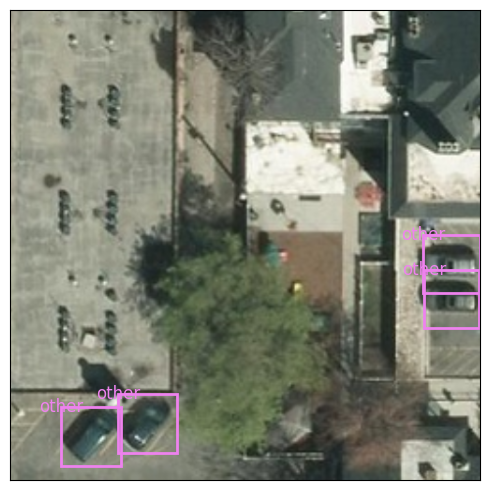

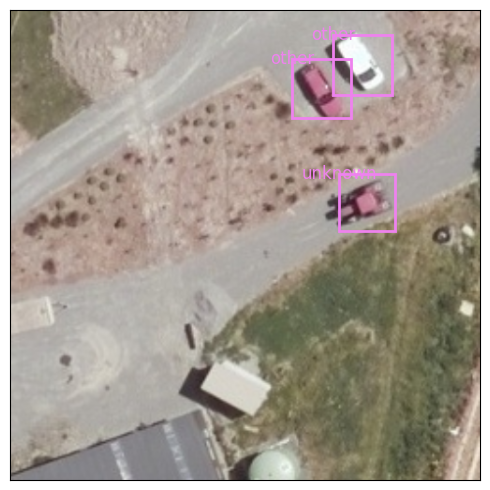

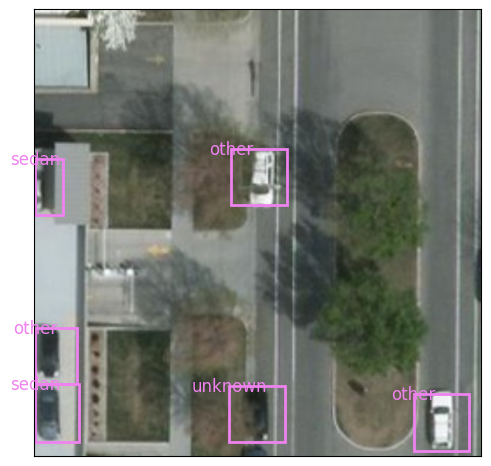

In [ ]:
model_config = {
    "num_classes": 5,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/cowc_m_object_detection/checkpoint.pth.tar"
labels = ["no-data","other","pickup","sedan","unknown"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/cowc_m_object_detection/datasets/DetectionPatches_256x256/Utah_AGRC/Utah_AGRC-HRO_15.0cm_12TVL240120.84.39.jpg')
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/cowc_m_object_detection/datasets/DetectionPatches_256x256/Selwyn_LINZ/Selwyn_BX22_Tile_RIGHT_15cm_0001.62.54.jpg')
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/cowc_m_object_detection/datasets/DetectionPatches_256x256/Utah_AGRC/Utah_AGRC-HRO_15.0cm_12TVL240120.15.5.jpg')
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)